# Results analysis — final 10K study

One combined comparison of **all six models**: linear regression, ridge, polynomial ridge, Random Forest, XGBoost and the preferred MLP. The main study uses 7,000 training / 1,500 validation / 1,500 test plants.

This notebook reads the published predictions and evidence; it does not retrain, load checkpoints, or save external results. The six neighboring model notebooks reconstruct training independently. Repeated plots from the former baseline and MLP validation notebooks are consolidated here. Supplemental stress tests compare the three nonlinear models and the numerical reference, rather than all six models.

In [1]:
from pathlib import Path
import os, sys, json, tempfile
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'mlpid-results-mpl'))
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
FINAL_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/data_gen.py').is_file())
sys.path.insert(0, str(FINAL_ROOT / 'scripts'))
sys.path.insert(0, str(FINAL_ROOT / 'src'))
from report_final_10000 import load_final, learning_plot as final_learning_plot, history_plot as final_history_plot
from plotting import (style, performance_plot, prediction_plot, failure_plot, objective_plot, itae_plot,
    overshoot_plot, overshoot_bins_plot, example_rows, response_plot)
final_names = ['linear', 'ridge', 'polynomial_ridge', 'random_forest', 'xgboost', 'standard_mlp']
FINAL_RESULTS = FINAL_ROOT / 'results' / 'dataset_final_10000'
final_metrics, final_predictions, final_protocol = load_final(final_names)
style()
display(final_metrics[['passes','plants','success_pct','stable_pct','r2','median_ITAE_ratio','median_J_ratio','ratio_pairs']])
display(pd.read_csv(FINAL_RESULTS / 'selected_before_test.csv').query('model in @final_names')[['model','setting','success_pct','median_J_ratio']])
print('Dataset SHA-256:', final_protocol['dataset_sha256'])

,passes,plants,success_pct,stable_pct,r2,median_ITAE_ratio,median_J_ratio,ratio_pairs
model,,,,,,,,
linear,437,1500,29.133333,71.333333,0.391862,3.409186,2.669074,437
ridge,442,1500,29.466667,71.733333,0.396986,3.337538,2.560768,442
polynomial_ridge,620,1500,41.333333,82.066667,0.665493,2.604814,2.105123,620
random_forest,1301,1500,86.733333,100.000000,0.940967,1.067729,1.065512,1301
xgboost,1272,1500,84.800000,100.000000,0.957534,1.136830,1.122313,1272
standard_mlp,1406,1500,93.733333,100.000000,0.979401,1.057748,1.057760,1406


,model,setting,success_pct,median_J_ratio
0,linear,fixed,28.800000,2.505865
1,ridge,alpha100,29.200000,2.509557
2,polynomial_ridge,degree2_alpha1,44.600000,2.100900
3,random_forest,depthNone_leaf1,86.933333,1.056718
4,xgboost,trees400,85.333333,1.114237
5,standard_mlp,standard,95.333333,1.061717


Dataset SHA-256: e86f0039c0747afa186a322bdc89f77b99f03a1ba9aaa77a40c6243e64d97089


## Regression accuracy and controller acceptance

Gain errors use all 1,500 test plants, including failed controllers. Acceptance requires finite bounded gains, stable poles, refined overshoot ≤10%, a settled tail and resolved numerical checks. Predictions are evaluated without clipping or a fallback.

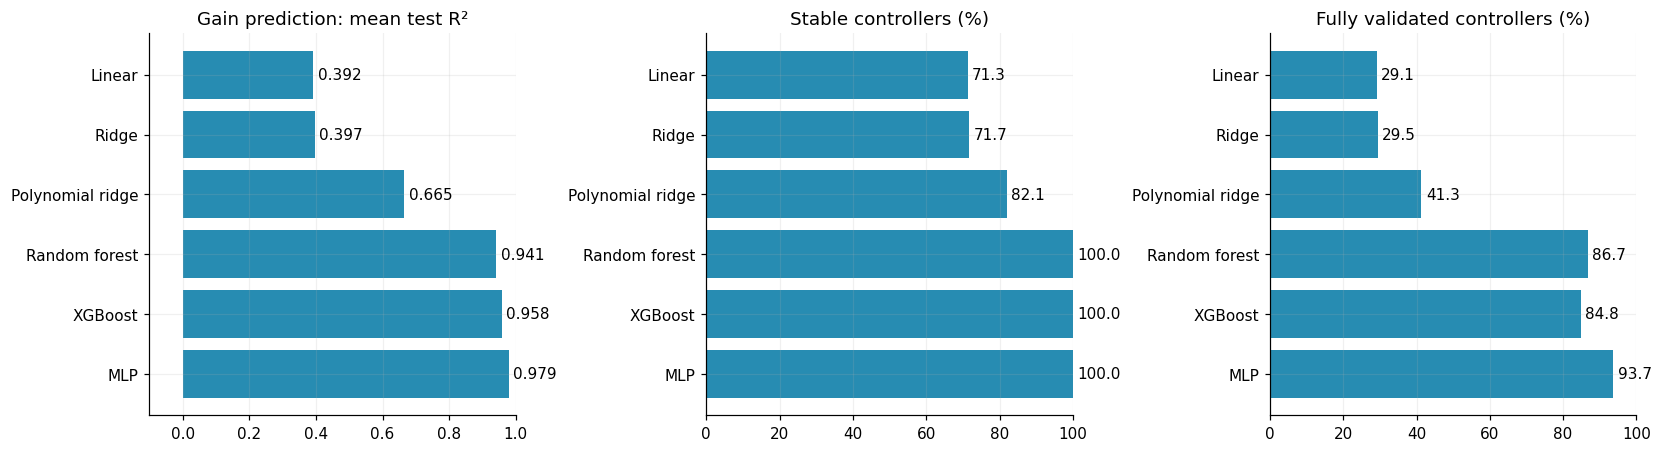

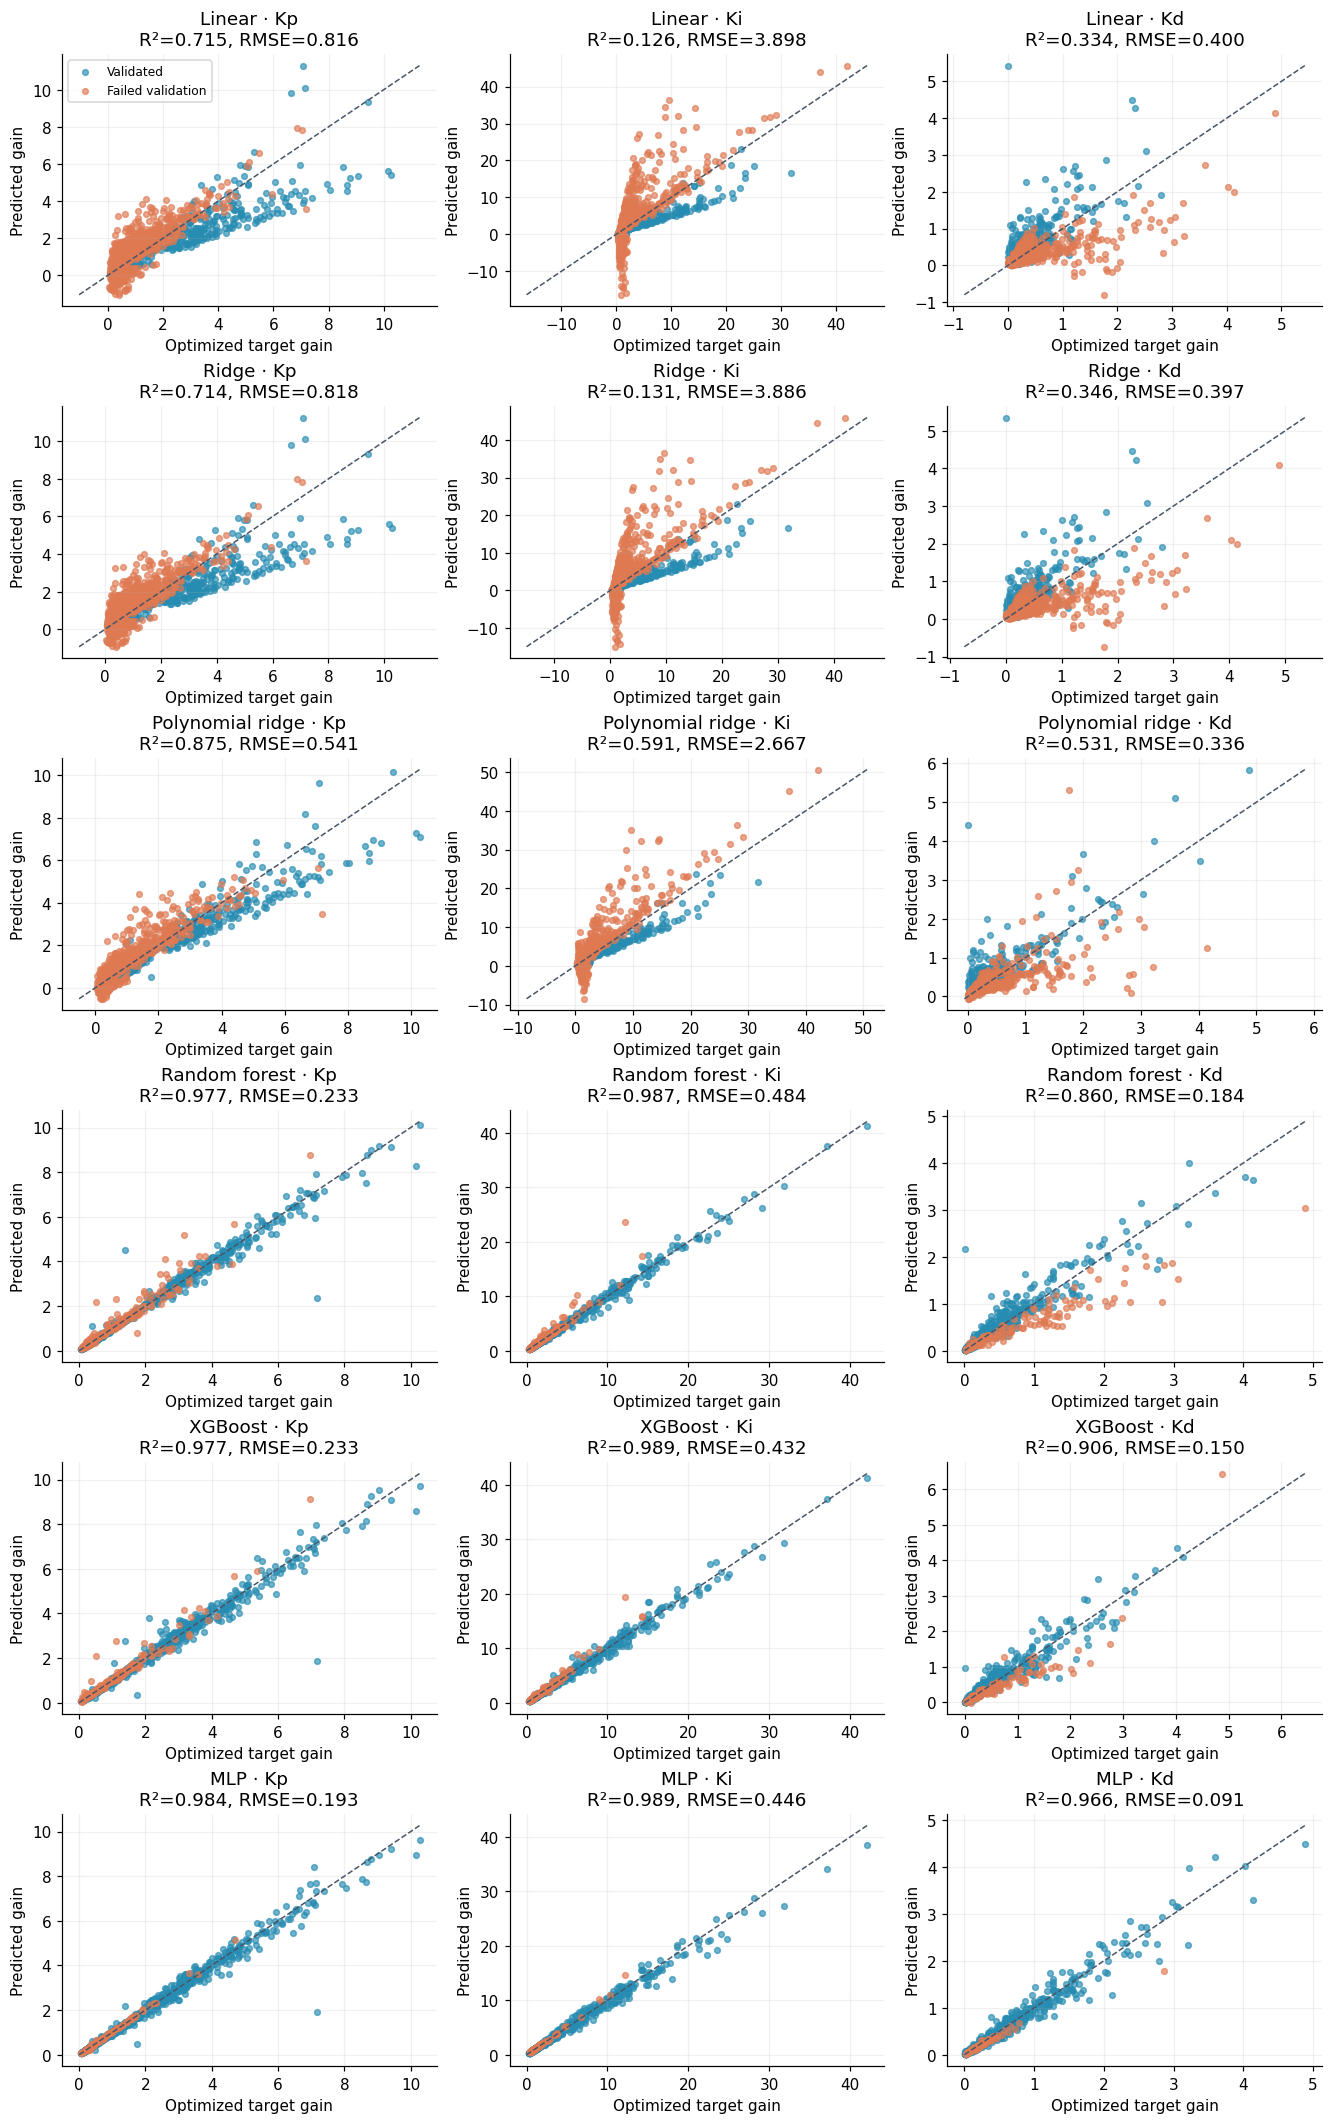

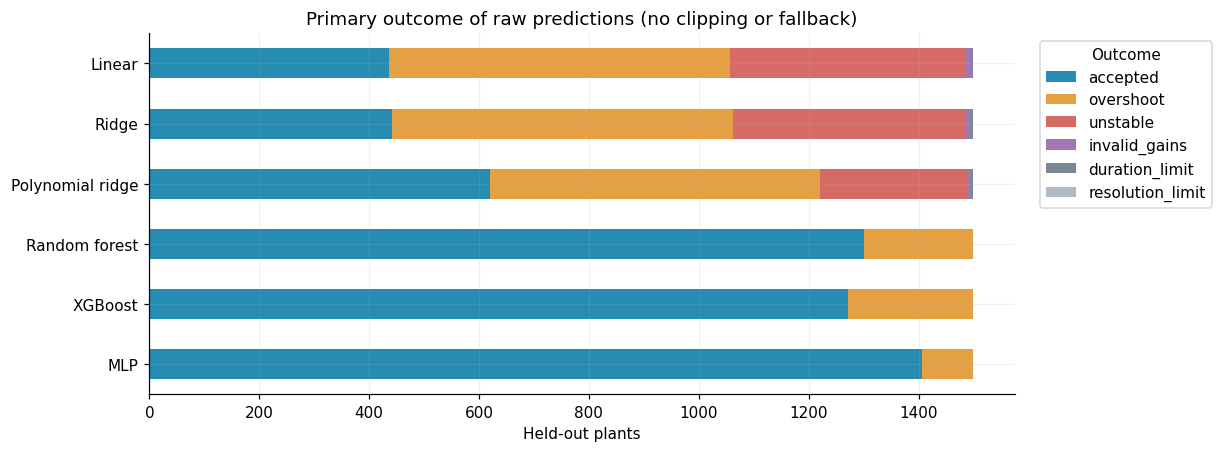

,model,gain,MAE,RMSE,R2
0,linear,Kp,0.561345,0.816017,0.715433
1,linear,Ki,2.168009,3.898288,0.125878
2,linear,Kd,0.192079,0.400083,0.334277
3,ridge,Kp,0.559628,0.817764,0.714213
4,ridge,Ki,2.155082,3.886321,0.131236
5,ridge,Kd,0.190887,0.396694,0.345509
6,polynomial_ridge,Kp,0.346111,0.541451,0.874713
7,polynomial_ridge,Ki,1.387686,2.667071,0.590840
8,polynomial_ridge,Kd,0.145532,0.335834,0.530925
9,random_forest,Kp,0.077666,0.232713,0.976857


In [2]:
# Gain agreement does not by itself certify a usable controller.
for final_plotter in [performance_plot, prediction_plot, failure_plot]:
    final_figure = final_plotter(final_metrics if final_plotter is performance_plot else final_predictions)
    plt.show()
    plt.close(final_figure)
display(pd.read_csv(FINAL_RESULTS / 'gain_errors.csv').query('model in @final_names'))

## ITAE and regularized cost relative to numerical tuning

**ITAE ratio = predicted ITAE / reference ITAE.** One means equal tracking cost. Percentage change is 100 × (ratio − 1). Ratios use only pairs where both controllers pass; coverage is shown and differs across models. Inspect upper tails as well as medians. The teacher minimizes J = ωₙ² ITAE + 0.01 times a dimensionless squared-gain penalty, so lower raw ITAE need not imply lower J.

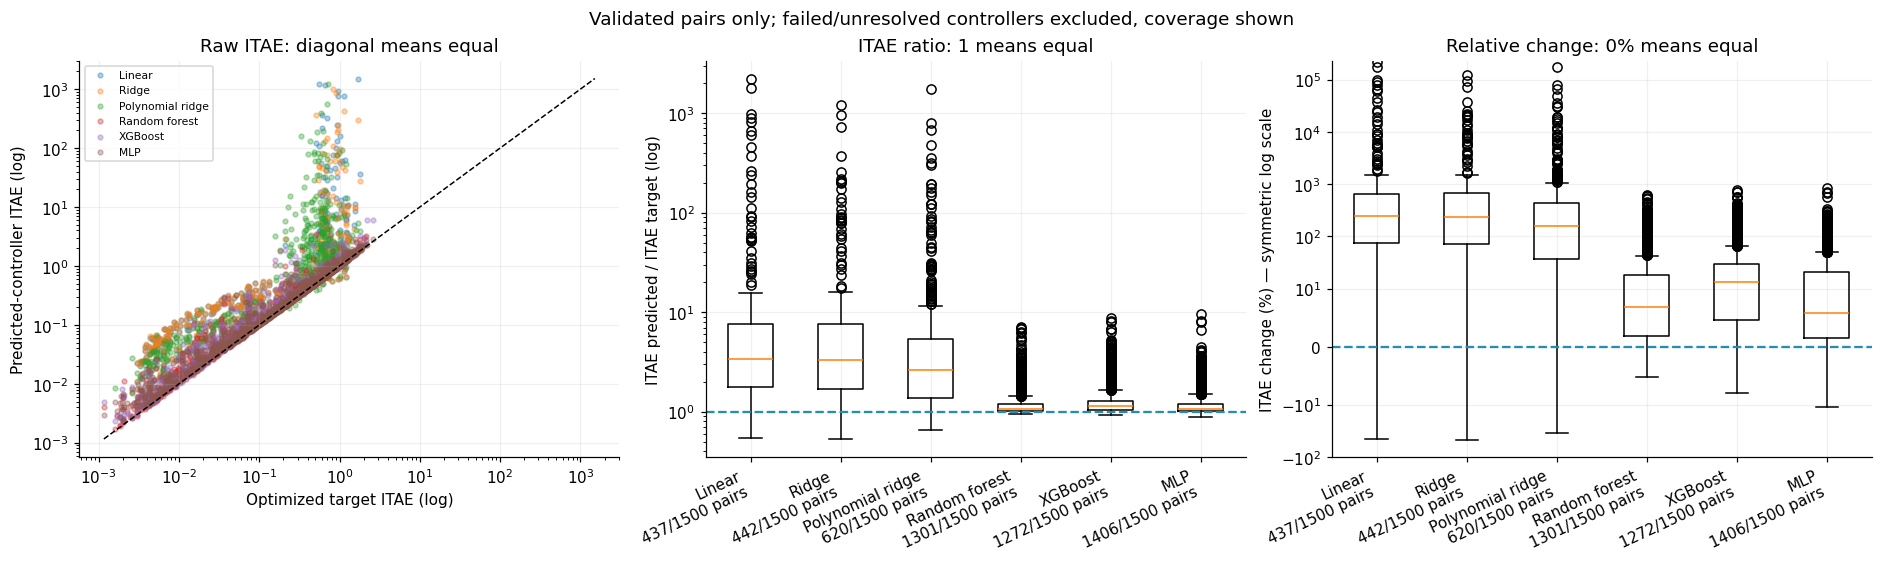

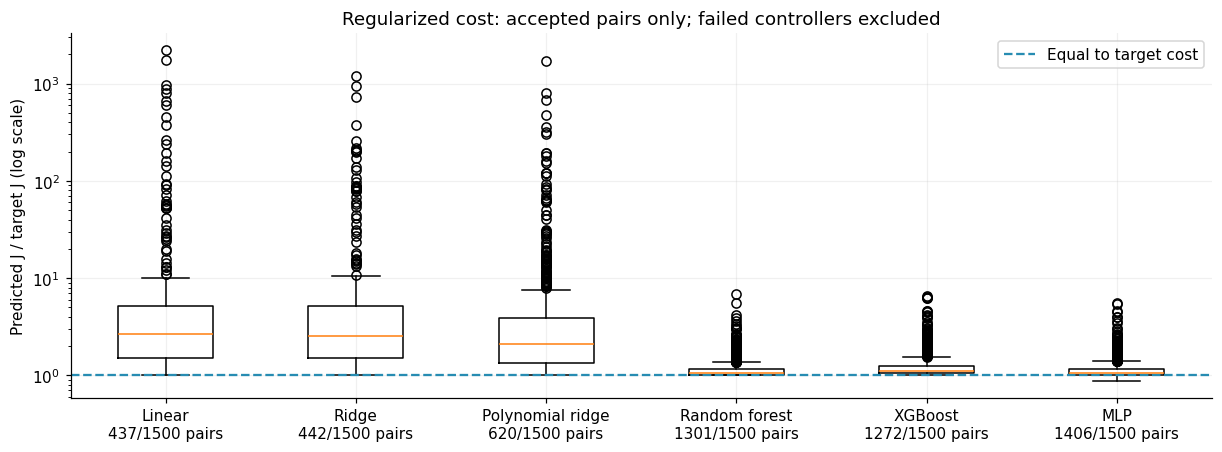

,model,pairs,median_ITAE_ratio,median_change_pct,p90_ITAE_ratio,p95_ITAE_ratio,max_ITAE_ratio,ITAE_over_2x
0,linear,437,3.409186,240.918562,12.750232,55.172987,2222.854519,306
1,ridge,442,3.337538,233.753821,12.928378,60.337431,1205.636791,309
2,polynomial_ridge,620,2.604814,160.481412,12.261858,30.344617,1725.416351,356
3,random_forest,1301,1.067729,6.772936,1.537953,1.971886,7.155548,63
4,xgboost,1272,1.136830,13.682982,1.801617,2.518548,8.745563,98
5,standard_mlp,1406,1.057748,5.774802,1.599990,2.103508,9.612143,78


In [3]:
for final_plotter in [itae_plot, objective_plot]:
    final_figure = final_plotter(final_predictions)
    plt.show()
    plt.close(final_figure)
display(pd.read_csv(FINAL_RESULTS / 'itae_summary.csv').query('model in @final_names'))

## Overshoot severity and error groups

The threshold curve uses **all 1,500 test plants** as its denominator. Unstable and unmeasured responses are separate, not assigned zero overshoot. Overshoot below 10% alone is not full acceptance. Physical delay/damping groups are descriptive audits, not prediction inputs or grounds for retuning.

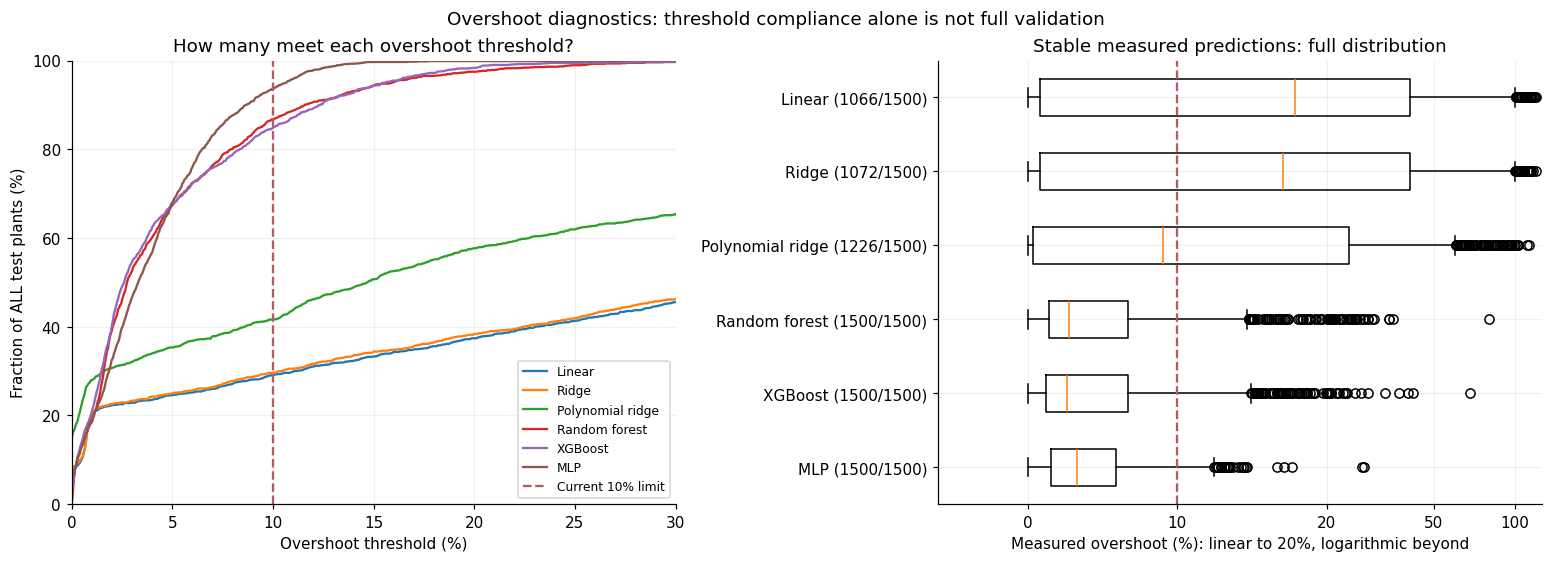

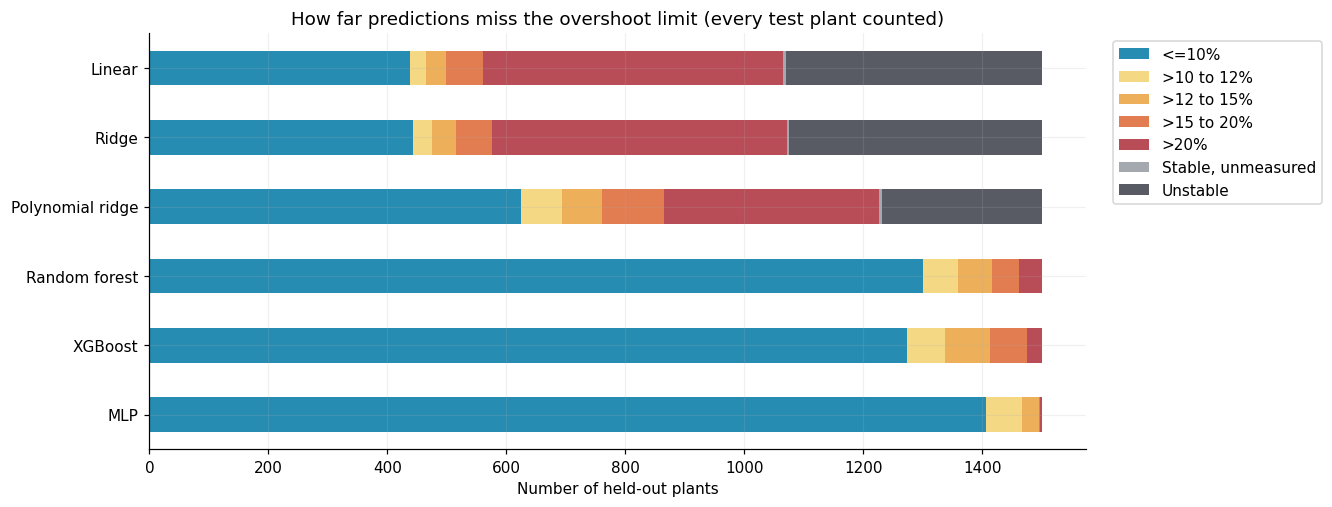

,model,test_plants,measured_stable,at_most_10,over_10_to_12,over_12_to_15,over_15_to_20,over_20,stable_unmeasured,unstable,median_overshoot_pct,p90_overshoot_pct,max_overshoot_pct,median_excess_pp,p90_excess_pp,full_validation_passes
0,linear,1500,1066,438,27,34,62,505,4,430,17.890344,65.718007,120.158204,24.792048,65.705768,437
1,ridge,1500,1072,444,31,41,60,496,4,424,17.061015,64.584853,119.628307,24.821010,64.679858,442
2,polynomial_ridge,1500,1226,624,69,68,104,361,5,269,9.044798,46.690969,113.491388,14.639505,51.071006,620
3,random_forest,1500,1500,1301,58,57,46,38,0,0,2.756464,11.564511,80.031357,4.339645,14.211811,1301
4,xgboost,1500,1500,1273,65,76,61,25,0,0,2.608828,12.289599,68.463764,3.751705,10.164936,1272
5,standard_mlp,1500,1500,1406,61,28,3,2,0,0,3.300628,8.658827,27.527092,1.426315,4.205017,1406


,model,reason,plants
0,linear,overshoot,620
1,linear,accepted,437
2,linear,unstable,430
3,linear,invalid_gains,8
4,linear,duration_limit,4
5,linear,resolution_limit,1
6,ridge,overshoot,620
7,ridge,accepted,442
8,ridge,unstable,424
9,ridge,invalid_gains,8


,model,group,plants,passes,success_pct
0,linear,zero delay,154,105,68.181818
1,linear,0 < delay <= 0.1,122,63,51.639344
2,linear,0.1 < delay <= 0.5,552,90,16.304348
3,linear,delay > 0.5,672,179,26.636905
4,linear,zeta < 0.5,317,17,5.362776
5,linear,0.5 <= zeta < 1,373,52,13.941019
6,linear,zeta >= 1,810,368,45.432099
7,ridge,zero delay,154,105,68.181818
8,ridge,0 < delay <= 0.1,122,63,51.639344
9,ridge,0.1 < delay <= 0.5,552,89,16.123188


In [4]:
for final_plotter in [overshoot_plot, overshoot_bins_plot]:
    final_figure = final_plotter(final_predictions)
    plt.show()
    plt.close(final_figure)
display(pd.read_csv(FINAL_RESULTS / 'overshoot_summary.csv').query('model in @final_names'))
display(pd.read_csv(FINAL_RESULTS / 'failure_counts.csv').query('model in @final_names'))
display(pd.read_csv(FINAL_RESULTS / 'group_results.csv').query('model in @final_names'))

## Learning curves: validation data only

All curves use the same fixed 500-plant validation subset and fixed selected settings. The extended curves use nested 1K, 3K, 5K, 7K, 10K, 15K and 20K **training** sets. They retain the original 7K training plants, then add independent development plants from the earlier 20K cohort. The dashed 7K marker corresponds to the chosen 10K-total dataset.

These are validation-guided development diagnostics, not repeated tests on the final holdout. Larger training sets still help; 10K total is a practical study budget, not demonstrated saturation. Single-seed curves are not confidence intervals.

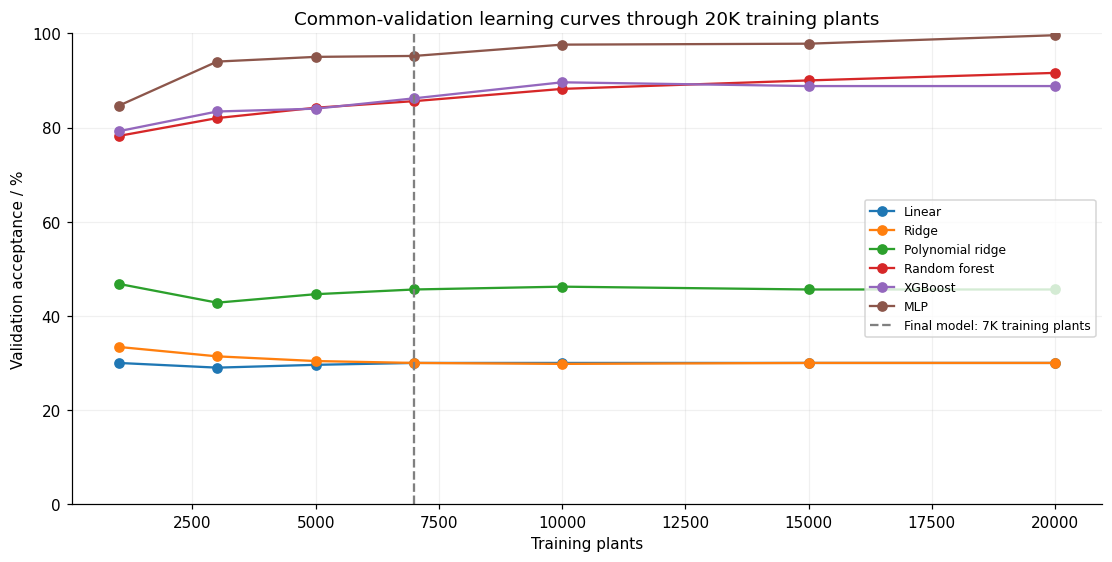

,model,training_size,success_pct,r2,median_J_ratio
6,linear,1000,30.0,0.519748,2.461049
7,linear,3000,29.0,0.516312,2.657663
8,linear,5000,29.6,0.518464,2.613888
0,linear,7000,30.0,0.521331,2.701603
24,linear,10000,30.0,0.519036,2.768190
25,linear,15000,30.0,0.520904,2.762836
26,linear,20000,30.0,0.521266,2.713691
12,polynomial_ridge,1000,46.8,0.673170,2.097739
13,polynomial_ridge,3000,42.8,0.681918,2.166171
14,polynomial_ridge,5000,44.6,0.688521,2.111416


In [5]:
from plotting import LABELS
curve_path = FINAL_RESULTS / 'website_extension/learning_curves.csv'
curves = pd.read_csv(curve_path)
fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
for name in final_names:
    group = curves[curves.model.eq(name)].sort_values('training_size')
    ax.plot(group.training_size, group.success_pct, 'o-', label=LABELS[name])
ax.axvline(7000, color='grey', linestyle='--', label='Final model: 7K training plants')
ax.set(xlabel='Training plants', ylabel='Validation acceptance / %', ylim=(0, 100),
       title='Common-validation learning curves through 20K training plants')
ax.legend(fontsize=8)
plt.show()
plt.close(fig)
display(curves.query('model in @final_names').sort_values(['model','training_size'])[
    ['model','training_size','success_pct','r2','median_J_ratio']])

## MLP training and early stopping

Three hidden layers (128, 64, 32), SiLU, dropout 0.05, positive normalized outputs and standardized log loss. Training restores the best validation-loss epoch; these curves do not alter the frozen model.

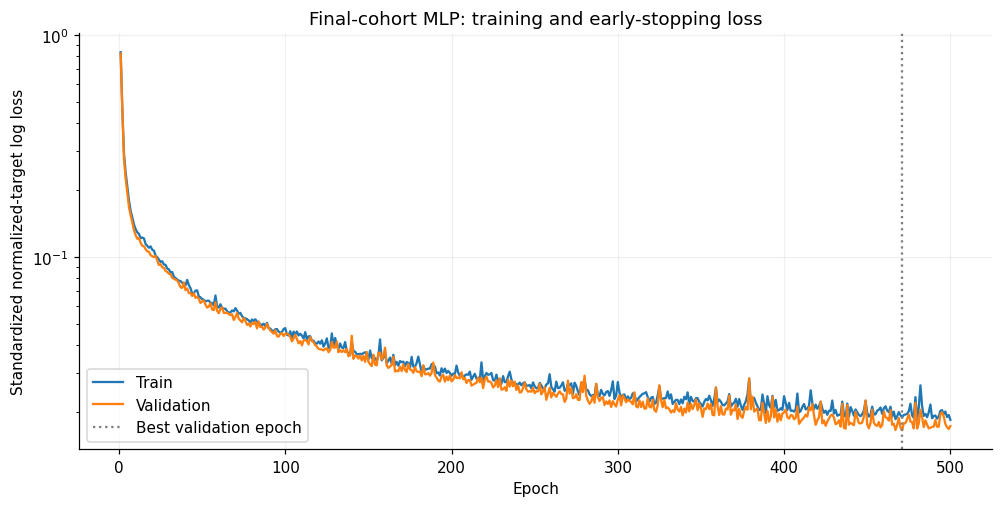

In [6]:
final_figure = final_history_plot()
plt.show()
plt.close(final_figure)

## Shared response examples

These examples are selected transparently from random-forest outcomes (median accepted J ratio and median stable overshoot miss). They illustrate behavior rather than estimate overall accuracy. Plotting stored gains does not rerun model selection or full test validation.

Representative RF success              8150
Representative RF overshoot failure    5607
Zero-delay example                       38
Name: Final-cohort CSV row, dtype: int64

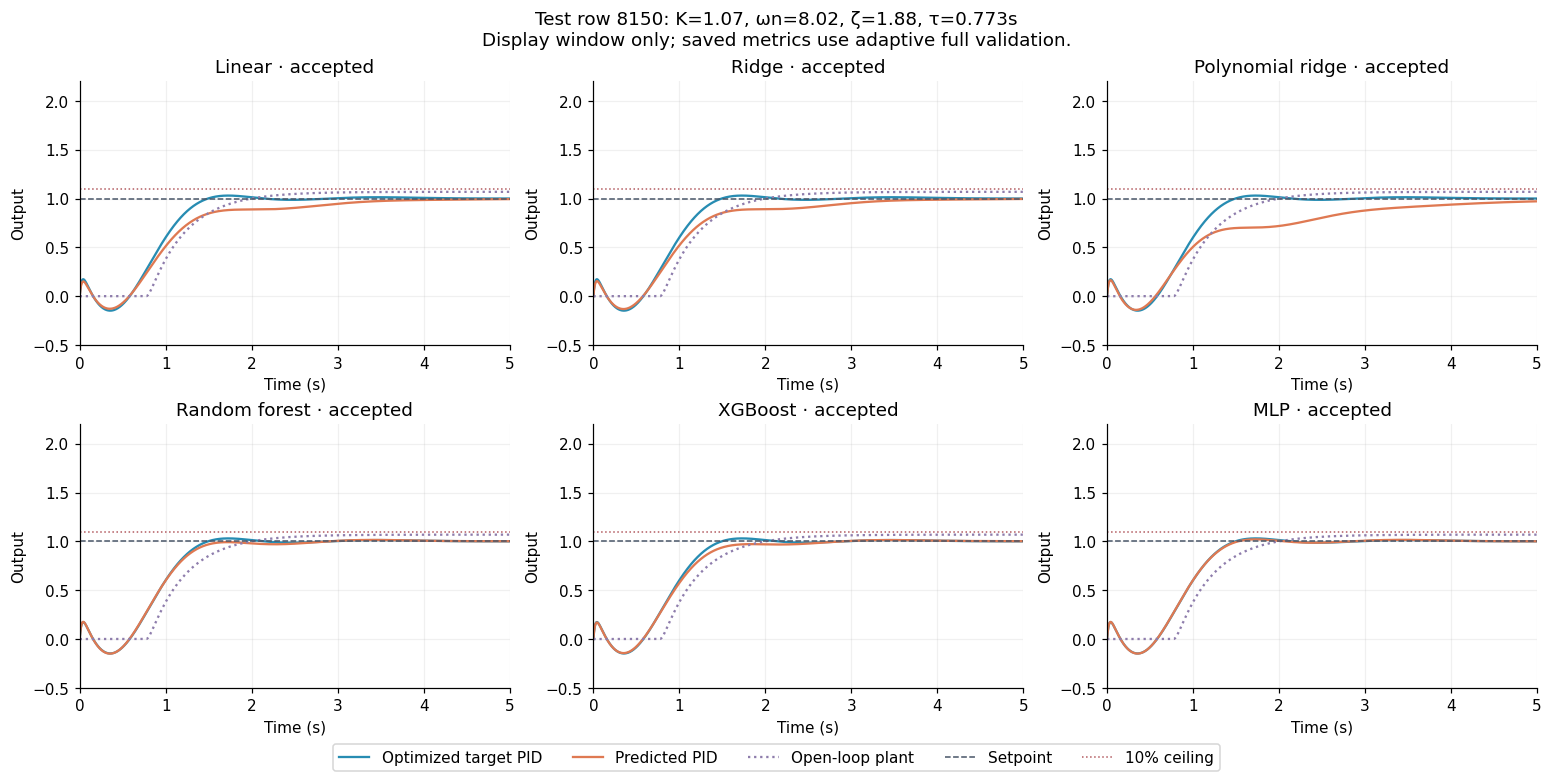

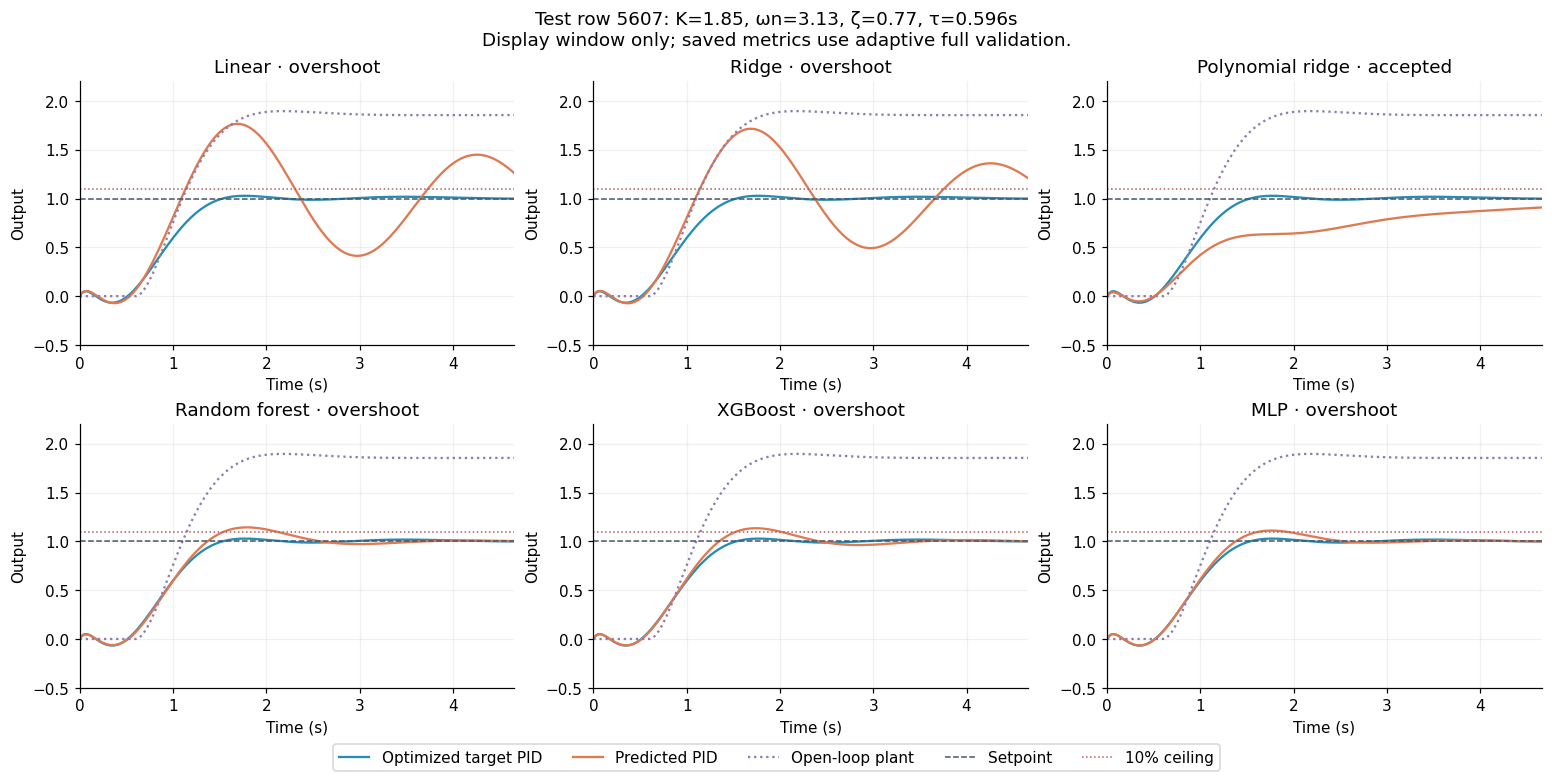

In [7]:
final_examples = example_rows(final_predictions)
display(pd.Series(final_examples, name='Final-cohort CSV row'))
for final_case in ['Representative RF success','Representative RF overshoot failure']:
    final_figure = response_plot(final_predictions, final_examples[final_case])
    plt.show()
    plt.close(final_figure)

## Verification and limits

The numerical target controllers were revalidated, all saved models reproduce their scored gains, and locked model/settings/data hashes remain unchanged. The held-out scores concern one split and seed within the accepted-label SOPDT population. Ideal PID and second-order Padé delay are approximations; there is no exact-delay, actuator/noise or hardware safety guarantee. Earlier 20K results use a different test cohort and are not a controlled sample-size comparison.

Full report: `results/dataset_final_10000/report.md`. Reproduce training with `python scripts/train_final_10000.py` in a separate unscored workspace; the runner deliberately refuses to overwrite this locked experiment.

The original checkpoint audit is historical evidence. Original Python checkpoints are no longer distributed; the six model notebooks reconstruct fitting and held-out evaluation without saving checkpoints.

In [8]:
display(pd.read_csv(FINAL_RESULTS / 'acceptance_intervals.csv').query('model in @final_names'))
display(json.loads((FINAL_RESULTS / 'verification.json').read_text(encoding='utf-8')))

,model,acceptance_pct,Wilson95_low,Wilson95_high
0,linear,29.133333,26.889535,31.483737
1,ridge,29.466667,27.214376,31.823859
2,polynomial_ridge,41.333333,38.866556,43.844387
3,random_forest,86.733333,84.922500,88.356501
4,xgboost,84.800000,82.894389,86.527823
5,standard_mlp,93.733333,92.391603,94.851636


{'split_sizes': {'train': 7000, 'validation': 1500, 'test': 1500},
 'dataset_hash_unchanged': True,
 'all_locked_artifact_hashes_unchanged': True,
 'saved_prediction_max_abs_difference': {'linear': 0.0,
  'ridge': 0.0,
  'polynomial_ridge': 0.0,
  'random_forest': 2.1316282072803006e-14,
  'xgboost': 0.0,
  'standard_mlp': 0.0},
 'validation_reference_accepted': 1500,
 'test_reference_accepted': 1500,
 'test_scored_once_per_model': True,
 'seconds': 1078.5060755000013}

## Stable overshoot misses remain measurable
The diagnostic evaluator continues after a 10% violation. It retains pole checks, grid/horizon convergence and tail limits. All MLP responses resolve; 94 exceed 10%. These controllers are not automatically useless. ITAE and settling ratios below describe the tradeoff, without changing the original acceptance criterion.

In [9]:
display(pd.read_csv(FINAL_RESULTS / 'final_checks/overshoot_band_quality.csv').query("model == 'standard_mlp'"))
display(pd.read_csv(FINAL_RESULTS / 'final_checks/threshold_sensitivity.csv').query("model == 'standard_mlp'"))

,model,band,plants,median_itae_ratio,p90_itae_ratio,median_settling_seconds,median_settling_ratio
25,standard_mlp,<=10%,1406,1.057748,1.599990,1.690989,1.090067
26,standard_mlp,10-12%,61,1.247705,1.712433,2.472095,1.242002
27,standard_mlp,12-15%,28,1.357943,1.702690,2.464735,1.381304
28,standard_mlp,15-20%,3,1.657282,1.889792,3.729308,2.140433
29,standard_mlp,>20%,2,2.630163,2.743378,3.434985,2.871173


,model,threshold_pct,plants,resolved_bounded_within_threshold,pct_all_plants
20,standard_mlp,10,1500,1406,93.733333
21,standard_mlp,12,1500,1467,97.800000
22,standard_mlp,15,1500,1495,99.666667
23,standard_mlp,20,1500,1498,99.866667


## Five frozen-model stress tests
Four tests share the same 100 plants (10 zero delay); boundaries add 241 fresh plants. Noise/uncertainty repeats are clustered by plant. The noisy-feature prediction study supplies the clean recording length and is separate from acquisition success. True-delay time-domain passes are not stability proofs.

In [10]:
for name in ['acquisition_summary','noise_summary','uncertainty_summary','boundary_groups_summary','exact_delay_comparison','disturbance_metrics']:
    print(name)
    display(pd.read_csv(FINAL_RESULTS / 'stress_tests' / (name + '.csv')))

acquisition_summary


,noise_fraction,cases,recording_pass_pct,usable_fixed_window_features_pct
0,0.0001,300,100.0,100.0
1,0.0005,300,0.0,100.0
2,0.0010,300,0.0,100.0
3,0.0050,300,0.0,100.0
4,0.0100,300,0.0,100.0
5,0.0200,300,0.0,100.0


noise_summary


,model,level,cases,passes,success_pct,base_plants,cluster_ci_low,cluster_ci_high,unstable_count,stability_unassessed_count,reason_counts,overshoot_measured,overshoot_median,overshoot_p95,overshoot_max,overshoot_over_20_count
0,random_forest,0.0001,300,255,85.000000,100,78.000000,91.000000,0,0,"{""accepted"": 255, ""overshoot"": 45}",300,3.265652,19.216383,80.037388,12
1,random_forest,0.0005,300,255,85.000000,100,78.000000,92.000000,0,0,"{""accepted"": 255, ""overshoot"": 45}",300,3.533104,19.084326,80.039828,11
2,random_forest,0.0010,300,244,81.333333,100,74.333333,88.000000,0,0,"{""accepted"": 244, ""overshoot"": 56}",300,3.316728,19.509055,92.479910,13
3,random_forest,0.0050,300,84,28.000000,100,21.333333,34.666667,99,0,"{""accepted"": 84, ""overshoot"": 117, ""unstable"":...",201,16.073486,87.300239,128.785959,84
4,random_forest,0.0100,300,29,9.666667,100,4.333333,15.666667,210,0,"{""accepted"": 29, ""duration_limit"": 1, ""oversho...",89,26.158851,88.808449,104.757578,49
5,random_forest,0.0200,300,25,8.333333,100,3.666667,13.675000,224,0,"{""accepted"": 25, ""overshoot"": 51, ""unstable"": ...",76,17.161346,87.536418,107.920198,35
6,xgboost,0.0001,300,232,77.333333,100,69.000000,85.333333,0,0,"{""accepted"": 232, ""overshoot"": 68}",300,3.901017,17.439970,69.173272,11
7,xgboost,0.0005,300,232,77.333333,100,69.000000,85.333333,0,0,"{""accepted"": 232, ""overshoot"": 68}",300,3.758226,17.442498,69.175053,9
8,xgboost,0.0010,300,232,77.333333,100,69.333333,85.000000,0,0,"{""accepted"": 232, ""overshoot"": 68}",300,3.700003,17.753618,69.178112,14
9,xgboost,0.0050,300,83,27.666667,100,21.333333,34.000000,103,0,"{""accepted"": 83, ""overshoot"": 114, ""unstable"":...",197,13.913988,80.250357,125.911565,83


uncertainty_summary


,model,level,cases,passes,success_pct,base_plants,cluster_ci_low,cluster_ci_high,unstable_count,stability_unassessed_count,reason_counts,overshoot_measured,overshoot_median,overshoot_p95,overshoot_max,overshoot_over_20_count
0,random_forest,0.05,500,402,80.4,100,73.4,87.200,0,0,"{""accepted"": 402, ""overshoot"": 98}",500,3.827693,20.177164,92.400374,27
1,random_forest,0.10,500,363,72.6,100,66.0,78.800,0,0,"{""accepted"": 363, ""overshoot"": 137}",500,4.691701,21.317473,98.671384,32
2,random_forest,0.20,500,314,62.8,100,56.6,69.000,2,0,"{""accepted"": 314, ""overshoot"": 184, ""unstable""...",498,6.247826,29.543999,95.124100,73
3,xgboost,0.05,500,389,77.8,100,69.8,84.800,0,0,"{""accepted"": 389, ""overshoot"": 111}",500,3.726020,17.892537,76.889483,15
4,xgboost,0.10,500,352,70.4,100,63.8,76.600,0,0,"{""accepted"": 352, ""overshoot"": 148}",500,5.002324,21.362352,78.863572,34
5,xgboost,0.20,500,312,62.4,100,55.8,68.800,0,0,"{""accepted"": 312, ""overshoot"": 188}",500,6.054028,31.987192,88.781250,77
6,standard_mlp,0.05,500,461,92.2,100,88.2,95.400,0,0,"{""accepted"": 461, ""overshoot"": 39}",500,3.276010,11.172637,19.447297,0
7,standard_mlp,0.10,500,413,82.6,100,78.6,86.600,0,0,"{""accepted"": 413, ""overshoot"": 87}",500,3.796402,16.145104,23.036018,7
8,standard_mlp,0.20,500,344,68.8,100,63.6,74.200,0,0,"{""accepted"": 344, ""overshoot"": 156}",500,4.925795,25.351524,43.728873,56
9,numerical_reference,0.05,500,495,99.0,100,97.4,100.000,0,0,"{""accepted"": 495, ""overshoot"": 5}",500,2.499589,7.730024,13.694543,0


... (2 outputs left out)

exact_delay_comparison


,model,plants,pade_passes,true_delay_time_domain_passes,median_itae_ratio,pade_pass_true_delay_overshoot
0,numerical_reference,100,100,89,1.012677,11
1,random_forest,100,85,68,1.013823,17
2,standard_mlp,100,97,84,1.006156,13
3,xgboost,100,78,68,1.012870,10


disturbance_metrics


,model,cases,recovered,median_peak_deviation,p95_peak_deviation,median_recovery_seconds,median_disturbance_itae
0,numerical_reference,100,100,0.062835,0.124220,2.09125,0.102038
1,random_forest,100,100,0.060505,0.124354,2.14625,0.103203
2,standard_mlp,100,100,0.060463,0.123707,2.11875,0.099880
3,xgboost,100,100,0.059899,0.124398,2.22474,0.105808


## Interpretation and reproducibility
MLP is strongest overall on the main study, but high-normalized-delay boundary cases can favor RF. Noise-sensitive feature extraction and Padé mismatch are major limitations. Larger training sets still help; 10K is a practical budget choice, not proven saturation. The root README describes environment setup, the individual training notebooks, rebuilding figures and full regeneration. The current reproduction workflow is documented in the repository README.